In [62]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.feature_selection import chi2
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score)

In [3]:
df=pd.read_csv("lifestyle weight tracker.csv")

In [11]:
df.columns

Index(['User_ID', 'Age', 'Gender', 'Height_cm', 'Initial_Weight_kg',
       'Stress_Level', 'Sleep_Hours', 'Caffeine_mg', 'Calories_Consumed',
       'Protein_g', 'Carbs_g', 'Fat_g', 'Steps', 'Workout_Type',
       'Workout_Intensity', 'Temp_C', 'Weight_Change', 'Current_Weight_kg'],
      dtype='object')

In [10]:
df.shape

(55000, 18)

In [4]:
df.head()

,User_ID,Age,Gender,Height_cm,Initial_Weight_kg,Stress_Level,Sleep_Hours,Caffeine_mg,Calories_Consumed,Protein_g,Carbs_g,Fat_g,Steps,Workout_Type,Workout_Intensity,Temp_C,Weight_Change,Current_Weight_kg
0,275,23,Female,169.355325,111.485330,10,7.016453,211.426469,2801.764291,175.1,315.2,93.4,8172,Strength,6,18.823955,0.317158,111.802488
1,296,43,Female,174.424939,109.699334,1,7.320227,211.979739,2666.001616,166.6,299.9,88.9,7988,NaN,0,36.987432,0.211877,109.911211
2,125,47,Male,163.246320,110.960286,3,7.238641,160.400067,1707.084012,106.7,192.0,56.9,7976,Yoga,10,35.977033,0.122390,111.082676
3,167,42,Female,164.997333,85.546097,7,5.060697,301.629856,2647.458547,165.5,297.8,88.2,8203,Cardio,10,33.141805,0.308449,85.854547
4,311,54,Male,167.696168,135.710505,5,9.866791,335.199126,2036.567163,127.3,229.1,67.9,8024,NaN,0,19.065076,0.120221,135.830726


In [5]:
df.tail()

,User_ID,Age,Gender,Height_cm,Initial_Weight_kg,Stress_Level,Sleep_Hours,Caffeine_mg,Calories_Consumed,Protein_g,Carbs_g,Fat_g,Steps,Workout_Type,Workout_Intensity,Temp_C,Weight_Change,Current_Weight_kg
54995,288,31,Female,172.989751,130.257318,6,5.791148,271.088251,2268.846150,141.8,255.2,75.6,7935,NaN,0,20.023635,0.175921,151.356362
54996,159,37,Male,179.688824,123.132106,9,7.691768,315.457575,1845.442138,115.3,207.6,61.5,7949,NaN,0,18.972702,0.175562,139.965519
54997,385,19,Female,167.302095,99.227392,3,8.340457,125.622338,NaN,150.0,269.9,80.0,7909,NaN,0,16.169056,0.113811,117.888421
54998,570,20,Male,178.401840,106.253039,10,5.833022,386.287965,2407.771582,150.5,270.9,80.3,7897,NaN,0,33.360536,0.340965,128.880845
54999,565,23,Male,175.664016,102.207143,10,10.402248,405.843037,1802.206215,112.6,202.7,60.1,7883,Strength,5,24.044327,0.215855,121.934377


In [6]:
df.describe()

,User_ID,Age,Height_cm,Initial_Weight_kg,Stress_Level,Sleep_Hours,Caffeine_mg,Calories_Consumed,Protein_g,Carbs_g,Fat_g,Steps,Workout_Intensity,Temp_C,Weight_Change,Current_Weight_kg
count,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,52250.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000
mean,349.441400,40.918545,169.972335,114.999924,5.524964,6.666340,261.091734,2097.729693,131.073911,235.932955,69.906169,7999.830891,3.496091,24.998172,0.168459,124.480910
std,144.343054,13.539751,9.991794,17.291936,2.881427,1.543146,114.579046,601.919105,37.583689,67.650694,20.044495,89.285148,3.776365,7.992403,0.105259,18.257341
min,100.000000,18.000000,126.190233,85.000325,1.000000,3.000000,0.000000,-327.404484,-20.500000,-36.800000,-10.900000,7632.000000,0.000000,-6.075821,-0.250723,85.327609
25%,224.000000,29.000000,163.273360,100.032148,3.000000,5.610998,181.968341,1693.339924,105.800000,190.500000,56.400000,7939.000000,0.000000,19.609512,0.096170,109.458941
50%,350.000000,41.000000,169.984098,115.032495,6.000000,6.659498,260.645919,2095.328161,130.900000,235.600000,69.800000,7999.000000,0.000000,24.996455,0.168383,124.555885
75%,474.000000,53.000000,176.675947,129.899387,8.000000,7.714812,339.196616,2501.645667,156.300000,281.325000,83.400000,8060.000000,7.000000,30.411654,0.241079,139.369026
max,599.000000,64.000000,213.837588,144.998228,10.000000,11.000000,740.175153,4874.404173,304.700000,548.400000,162.500000,8365.000000,10.000000,58.914302,0.593711,291.842383


In [7]:
df.isnull().sum()

User_ID                  0
Age                      0
Gender                   0
Height_cm                0
Initial_Weight_kg        0
Stress_Level             0
Sleep_Hours              0
Caffeine_mg              0
Calories_Consumed     2750
Protein_g                0
Carbs_g                  0
Fat_g                    0
Steps                    0
Workout_Type         27552
Workout_Intensity        0
Temp_C                   0
Weight_Change            0
Current_Weight_kg        0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   User_ID            55000 non-null  int64  
 1   Age                55000 non-null  int64  
 2   Gender             55000 non-null  object 
 3   Height_cm          55000 non-null  float64
 4   Initial_Weight_kg  55000 non-null  float64
 5   Stress_Level       55000 non-null  int64  
 6   Sleep_Hours        55000 non-null  float64
 7   Caffeine_mg        55000 non-null  float64
 8   Calories_Consumed  52250 non-null  float64
 9   Protein_g          55000 non-null  float64
 10  Carbs_g            55000 non-null  float64
 11  Fat_g              55000 non-null  float64
 12  Steps              55000 non-null  int64  
 13  Workout_Type       27448 non-null  object 
 14  Workout_Intensity  55000 non-null  int64  
 15  Temp_C             55000 non-null  float64
 16  Weight_Change      550

In [35]:
#replacing the null values
df['Calories_Consumed'] = df['Calories_Consumed'].fillna(df['Calories_Consumed'].median()) #because there are outliers
df['Workout_Type'].fillna(df['Workout_Type'].mode()[0], inplace=True)

In [36]:
df.isnull().sum()

User_ID              0
Age                  0
Gender               0
Height_cm            0
Initial_Weight_kg    0
Stress_Level         0
Sleep_Hours          0
Caffeine_mg          0
Calories_Consumed    0
Protein_g            0
Carbs_g              0
Fat_g                0
Steps                0
Workout_Type         0
Workout_Intensity    0
Temp_C               0
Weight_Change        0
Current_Weight_kg    0
dtype: int64

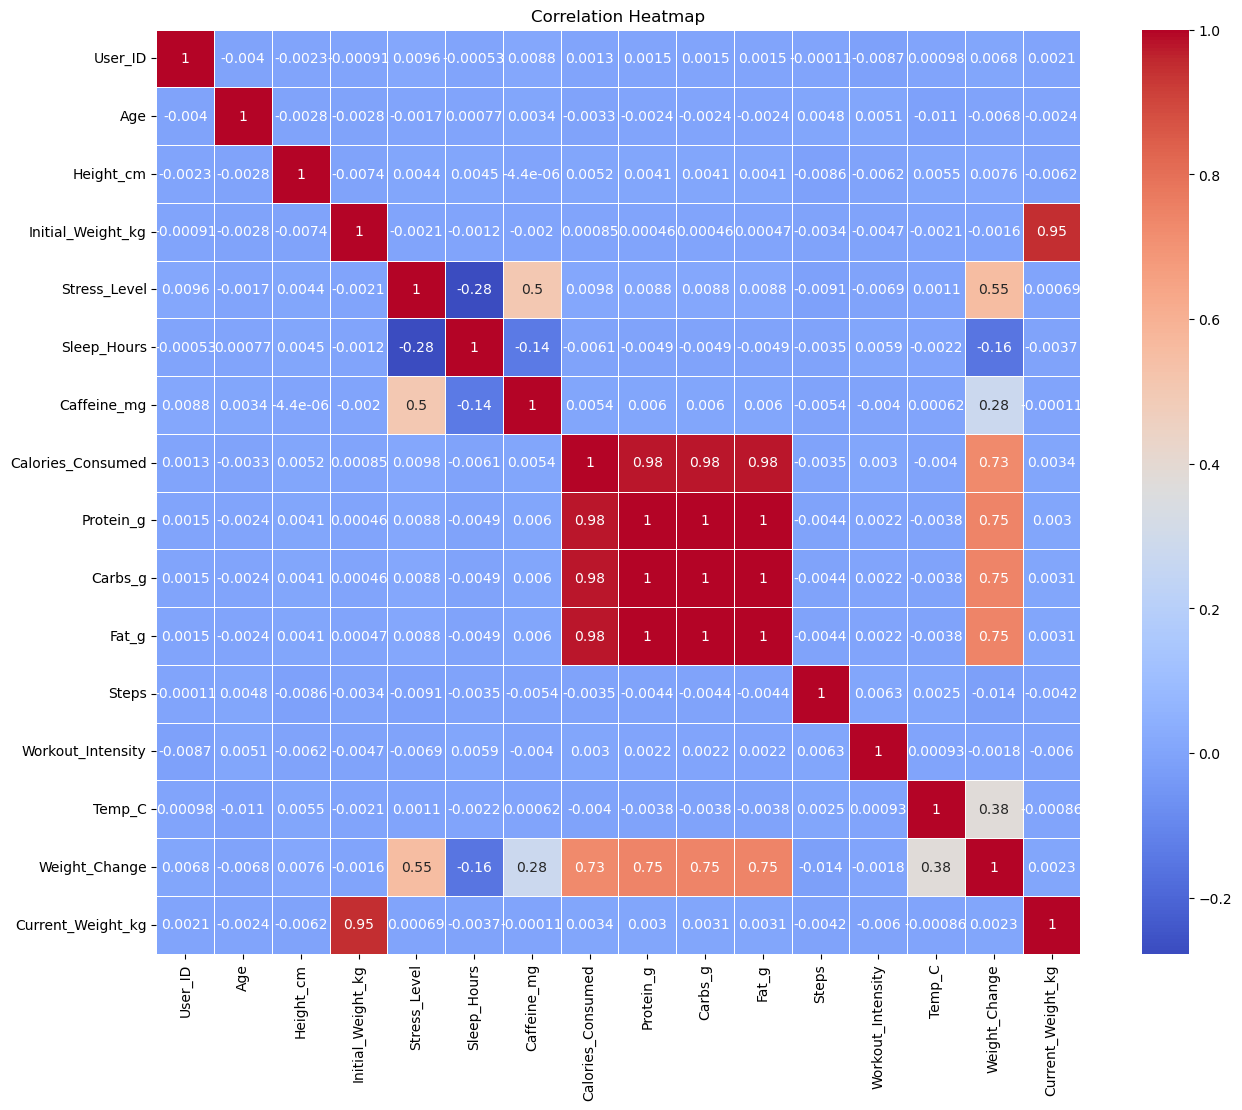

In [37]:
# corr for numeric only
numeric_df = df.select_dtypes(include=['int64', 'float64'])
plt.figure(figsize=(16, 12))
sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap='coolwarm',
            linewidths=0.5,
            square=True)
plt.title("Correlation Heatmap")
plt.show()

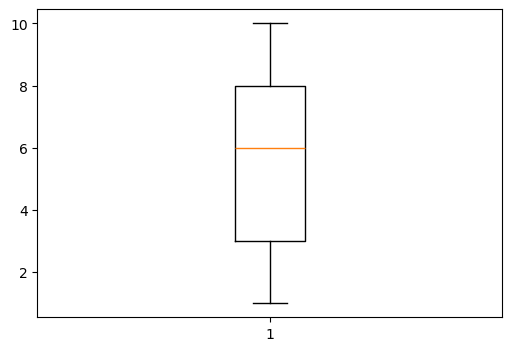

In [38]:
#boxplot
plt.figure(figsize=(6,4))
plt.boxplot(df['Stress_Level'])
plt.show()

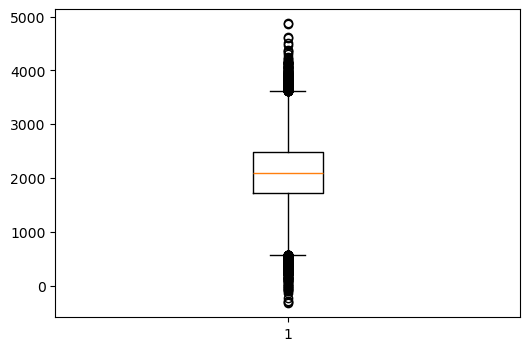

In [39]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Calories_Consumed'])
plt.show()

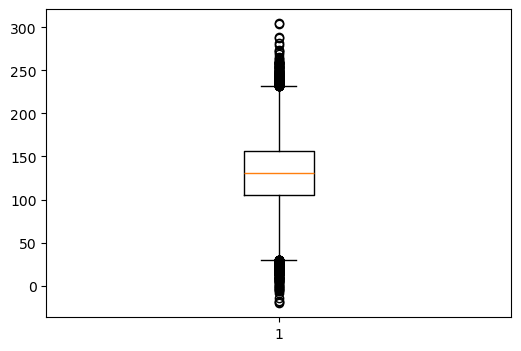

In [40]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Protein_g'])
plt.show()

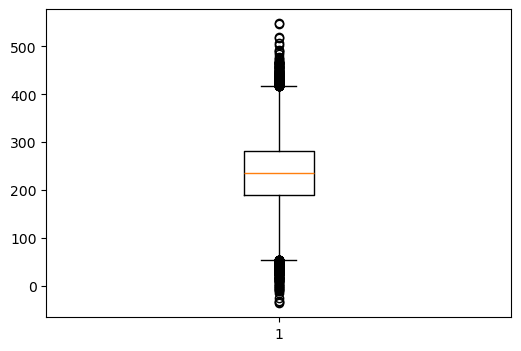

In [41]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Carbs_g'])
plt.show()

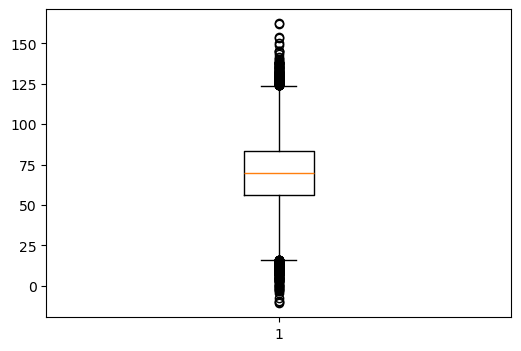

In [42]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Fat_g'])
plt.show()

In [43]:
#outlier replacing
Q1 = df['Calories_Consumed'].quantile(0.25)
Q3 = df['Calories_Consumed'].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
df['Calories_Consumed'] = df['Calories_Consumed'].clip(lower=lower_limit, upper=upper_limit)

In [44]:
#outlier replacing
Q1 = df['Protein_g'].quantile(0.25)
Q3 = df['Protein_g'].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
df['Protein_g'] = df['Protein_g'].clip(lower=lower_limit, upper=upper_limit)

In [45]:
#outlier replacing
Q1 = df['Carbs_g'].quantile(0.25)
Q3 = df['Carbs_g'].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
df['Carbs_g'] = df['Carbs_g'].clip(lower=lower_limit, upper=upper_limit)

In [46]:
#outlier replacing
Q1 = df['Fat_g'].quantile(0.25)
Q3 = df['Fat_g'].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
df['Fat_g'] = df['Fat_g'].clip(lower=lower_limit, upper=upper_limit)

In [47]:
#eda after data cleaning

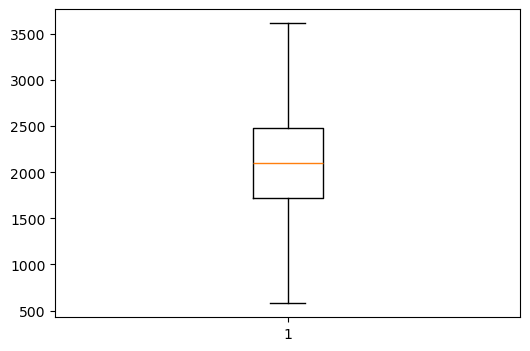

In [48]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Calories_Consumed'])
plt.show()

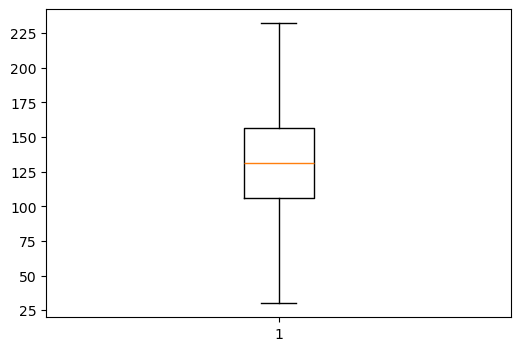

In [49]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Protein_g'])
plt.show()

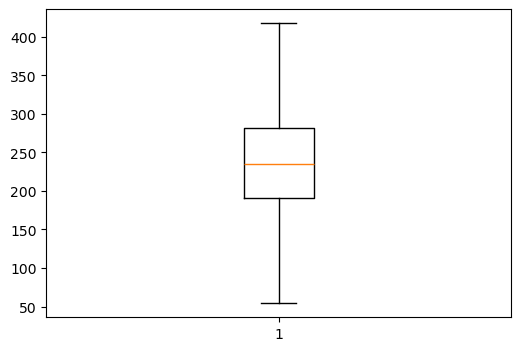

In [50]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Carbs_g'])
plt.show()

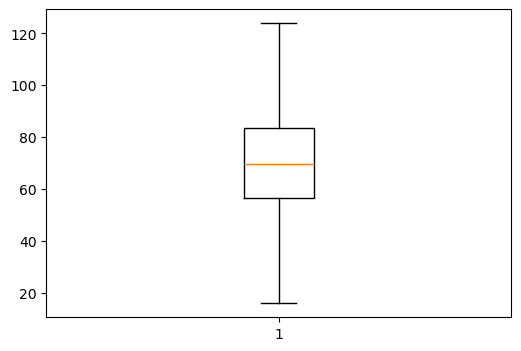

In [51]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Fat_g'])
plt.show()

In [52]:
#target variable
Y=df['Weight_Change']

In [53]:
#Independent Variable
X=df[['Stress_Level','Calories_Consumed','Protein_g','Carbs_g','Fat_g']]

In [54]:
#data transformation for X
SS=StandardScaler()
SS_X=SS.fit_transform(X)
SS_X=pd.DataFrame(SS_X)
SS_X.head()

,0,1,2,3,4
0,1.553077,1.212651,1.179159,1.179508,1.179677
1,-1.570404,0.978828,0.951515,0.951853,0.953733
2,-0.876297,-0.672706,-0.652712,-0.653633,-0.652973
3,0.511917,0.946892,0.922055,0.920606,0.918587
4,-0.182190,-0.105241,-0.101008,-0.101607,-0.100668


In [84]:
#data partiton
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [85]:
#model selection
lin_model=LinearRegression()

In [86]:
lin_model.fit(X_train,Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [87]:
y_train_pred = lin_model.predict(X_train)
y_test_pred = lin_model.predict(X_test)

In [88]:
print("train MAE :", mean_absolute_error(Y_train, y_train_pred))
print(" test MAE :", mean_absolute_error(Y_test, y_test_pred))
print("train MSE :", mean_squared_error(Y_train, y_train_pred))
print("test MSE :", mean_squared_error(Y_test, y_test_pred))
print("train RMSE:", root_mean_squared_error(Y_train, y_train_pred))
print("test RMSE:", root_mean_squared_error(Y_test, y_test_pred))
print("train R² Score:", r2_score(Y_train, y_train_pred))
print("test R² Score:", r2_score(Y_test, y_test_pred))
print("Training Score :", lin_model.score(X_train, Y_train))
print("Testing Score  :", lin_model.score(X_test, Y_test))

train MAE : 0.03201214628156866
 test MAE : 0.03172198859911002
train MSE : 0.0016095099106854765
test MSE : 0.0015804737479168678
train RMSE: 0.040118697769063696
test RMSE: 0.03975517259322198
train R² Score: 0.8542423132267143
test R² Score: 0.8592018803422306
Training Score : 0.8542423132267143
Testing Score  : 0.8592018803422306


In [89]:
#cross validaton
cv_scores = cross_val_score(lin_model,X,Y,cv=10,scoring='r2')
print("Cross Validation Scores:")
print(cv_scores)
print("Mean CV Score:", cv_scores.mean())

Cross Validation Scores:
[0.85282771 0.85541512 0.85343157 0.85030679 0.85580725 0.86050033
 0.85403769 0.85689951 0.85431478 0.8582585 ]
Mean CV Score: 0.8551799235067132


In [68]:
#predict new values

In [70]:
X.columns

Index(['Stress_Level', 'Calories_Consumed', 'Protein_g', 'Carbs_g', 'Fat_g'], dtype='object')

In [102]:
new_data = pd.DataFrame({
    'Stress_Level': [5],
    'Calories_Consumed': [2200],
    'Protein_g': [80],
    'Carbs_g': [250],
    'Fat_g': [70]
})
prediction = lin_model.predict(new_data)
print("Predicted Value:", prediction[0])

Predicted Value: -0.921963397207378


In [98]:
#save model

In [99]:
import pickle

with open("model.pkl", "wb") as file:
    pickle.dump(lin_model, file)

In [100]:
with open("scaler.pkl", "wb") as file:
    pickle.dump(SS, file)

In [101]:
feature_names = X.columns.tolist()

with open("features.pkl", "wb") as file:
    pickle.dump(feature_names, file)